In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


# Compare model training curves

This notebook plots CNN, BiLSTM, and URLBERT training logs on shared axes. The x-axis is normalized training progress, because CNN logs epochs while the other models log optimizer steps.

In [2]:
RESULTS = Path('../results')
LOGS = {
    'CNN': RESULTS / 'cnn_train_log.csv',
    'BiLSTM': RESULTS / 'bilstm_train_log.csv',
    'URLBERT': RESULTS / 'urlbert_train_log.csv',
}


In [3]:
runs = {}
for name, path in LOGS.items():
    if not path.exists():
        print(f'Skipping {name}: {path} does not exist')
        continue
    frame = pd.read_csv(path).copy()
    if frame.empty:
        print(f'Skipping {name}: log is empty')
        continue
    if 'step' in frame.columns:
        progress = frame['step'] / frame['step'].max() * 100
    else:
        progress = frame['epoch'] / frame['epoch'].max() * 100
    frame['progress'] = progress
    runs[name] = frame

if not runs:
    raise FileNotFoundError('No training logs were found in ../results')

display({name: tuple(frame.shape) for name, frame in runs.items()})

{'CNN': (5, 4), 'BiLSTM': (9, 10), 'URLBERT': (14, 10)}

In [4]:
loss_values = pd.concat(
    [frame[['train_loss', 'val_loss']] for frame in runs.values()],
    ignore_index=True,
)
loss_min = loss_values.min().min()
loss_max = loss_values.max().max()
loss_padding = max((loss_max - loss_min) * 0.05, 0.01)
shared_ylim = (max(0, loss_min - loss_padding), loss_max + loss_padding)
shared_xlim = (0, 100)
print('shared x-axis:', shared_xlim)
print('shared y-axis:', tuple(round(value, 4) for value in shared_ylim))

shared x-axis: (0, 100)
shared y-axis: (np.float64(0.2244), np.float64(0.419))


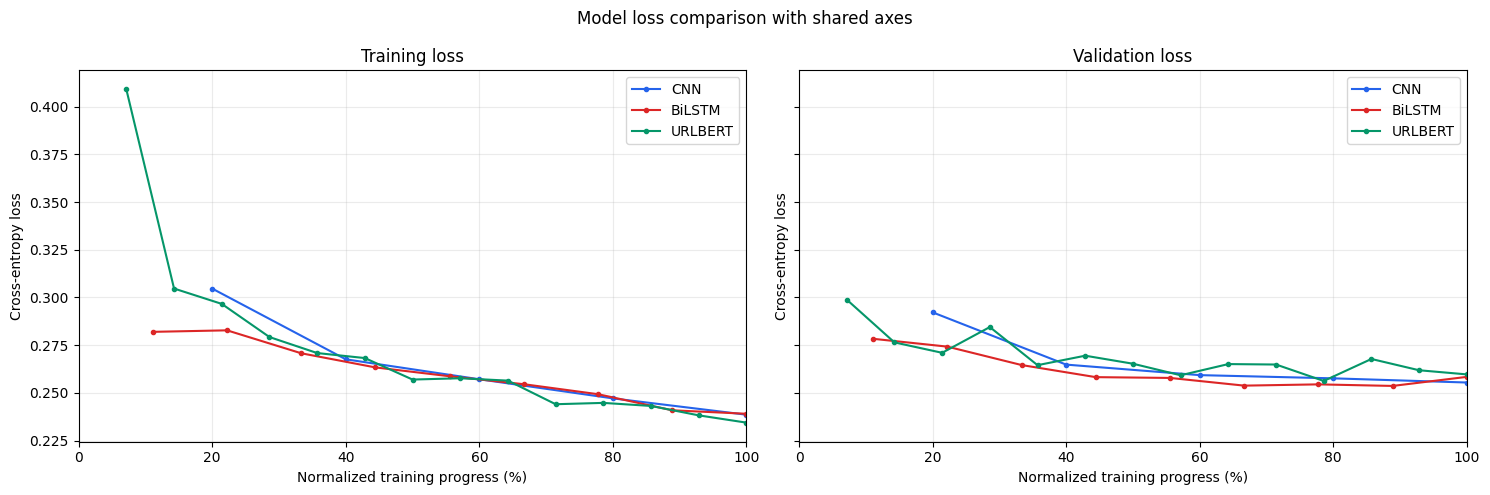

In [5]:
colors = {'CNN': '#2563eb', 'BiLSTM': '#dc2626', 'URLBERT': '#059669'}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True)

for name, frame in runs.items():
    color = colors.get(name, None)
    axes[0].plot(frame['progress'], frame['train_loss'], marker='o', ms=3, label=name, color=color)
    axes[1].plot(frame['progress'], frame['val_loss'], marker='o', ms=3, label=name, color=color)

for axis, title in zip(axes, ['Training loss', 'Validation loss']):
    axis.set_xlim(*shared_xlim)
    axis.set_ylim(*shared_ylim)
    axis.set_xlabel('Normalized training progress (%)')
    axis.set_ylabel('Cross-entropy loss')
    axis.set_title(title)
    axis.grid(True, alpha=0.25)
    axis.legend()

fig.suptitle('Model loss comparison with shared axes')
fig.tight_layout()
fig.savefig(RESULTS / 'training_loss_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
summary = []
for name, frame in runs.items():
    best_index = frame['val_loss'].idxmin()
    best = frame.loc[best_index]
    summary.append({
        'model': name,
        'best_val_loss': best['val_loss'],
        'best_val_f1': best.get('val_f1', float('nan')),
        'best_progress_%': best['progress'],
    })

display(pd.DataFrame(summary).set_index('model').round(4))

,best_val_loss,best_val_f1,best_progress_%
model,,,
CNN,0.2554,NaN,100.0000
BiLSTM,0.2536,0.8768,88.8889
URLBERT,0.2563,0.8716,78.5714
